In [1]:
# ==========================================
# AI-POWERED FX RISK INTELLIGENCE PLATFORM
# Week 2 - Session 2
# Volatility clustering and ARCH
# ==========================================

%pip install seaborn

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.stattools import jarque_bera

from scipy.stats import chi2


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Load clean FX dataset
df = pd.read_csv("../data/processed/cleaned_fx_data.csv", parse_dates = ["Date"])

# Sort observations chronologically
df = df.sort_values("Date")

# Set Date as index
df.set_index("Date", inplace=True)

# Display dataset
print(df.head())
print(df.info())

            GBPUSD_Close  GBPUSD_OHLC_Invalid  EURUSD_Close  \
Date                                                          
2021-11-03      1.361739                False      1.157943   
2021-11-04      1.369488                 True      1.161575   
2021-11-05      1.350860                False      1.155535   
2021-11-08      1.349127                False      1.156885   
2021-11-09      1.356451                False      1.159152   

            EURUSD_OHLC_Invalid  USDJPY_Close  USDJPY_OHLC_Invalid  
Date                                                                
2021-11-03                False    113.961998                False  
2021-11-04                False    114.070000                False  
2021-11-05                False    113.836998                False  
2021-11-08                False    113.474998                False  
2021-11-09                False    113.253998                 True  
<class 'pandas.DataFrame'>
DatetimeIndex: 1300 entries, 2021-11-03 to 2026-

C:\Users\alexb\AppData\Local\Temp\ipykernel_11056\1858182090.py:8: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index("Date", inplace=True)


In [6]:
# Define currency pairs
currency_pairs = ["GBPUSD_Close", "EURUSD_Close", "USDJPY_Close"]

# Calculate logarithmic returns
returns = np.log(df[currency_pairs] / df[currency_pairs].shift(1))

# Remove missing observations
returns = returns.dropna()

# Rename columns
returns.columns = ["GBPUSD", "EURUSD", "USDJPY"]

# Display returns 
print(returns.head())

# Summary statistics
print(returns.describe())


              GBPUSD    EURUSD    USDJPY
Date                                    
2021-11-04  0.005674  0.003131  0.000947
2021-11-05 -0.013695 -0.005213 -0.002045
2021-11-08 -0.001284  0.001168 -0.003185
2021-11-09  0.005414  0.001957 -0.001949
2021-11-10 -0.000332  0.000348 -0.003024
            GBPUSD       EURUSD       USDJPY
count  1299.000000  1299.000000  1299.000000
mean     -0.000011    -0.000026     0.000252
std       0.005275     0.004733     0.006206
min      -0.042324    -0.018590    -0.037961
25%      -0.002856    -0.002637    -0.002781
50%       0.000014    -0.000211     0.000685
75%       0.002868     0.002637     0.003548
max       0.030308     0.027537     0.025029


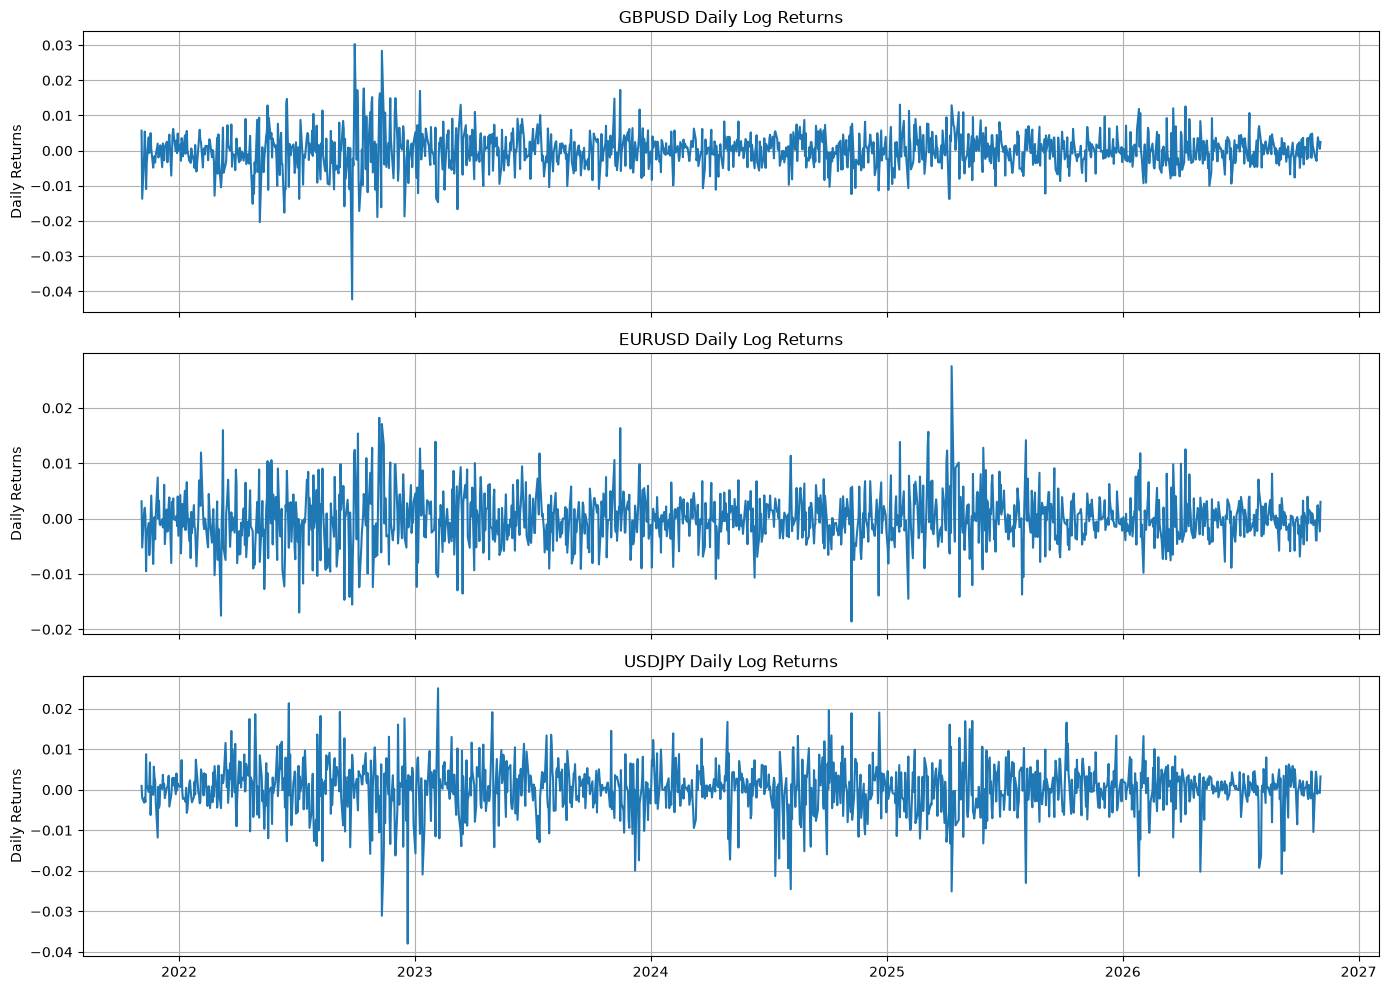

In [7]:
# Plot daily FX returns
fig, axes = plt.subplots(3, 1, figsize = (14, 10), sharex = True)

for i, pair in enumerate(returns.columns):
    axes[i].plot(returns.index, returns[pair])
    axes[i].set_title(f"{pair} Daily Log Returns")
    axes[i].set_ylabel("Daily Returns")
    axes[i].grid(True)
plt.tight_layout()
plt.show()

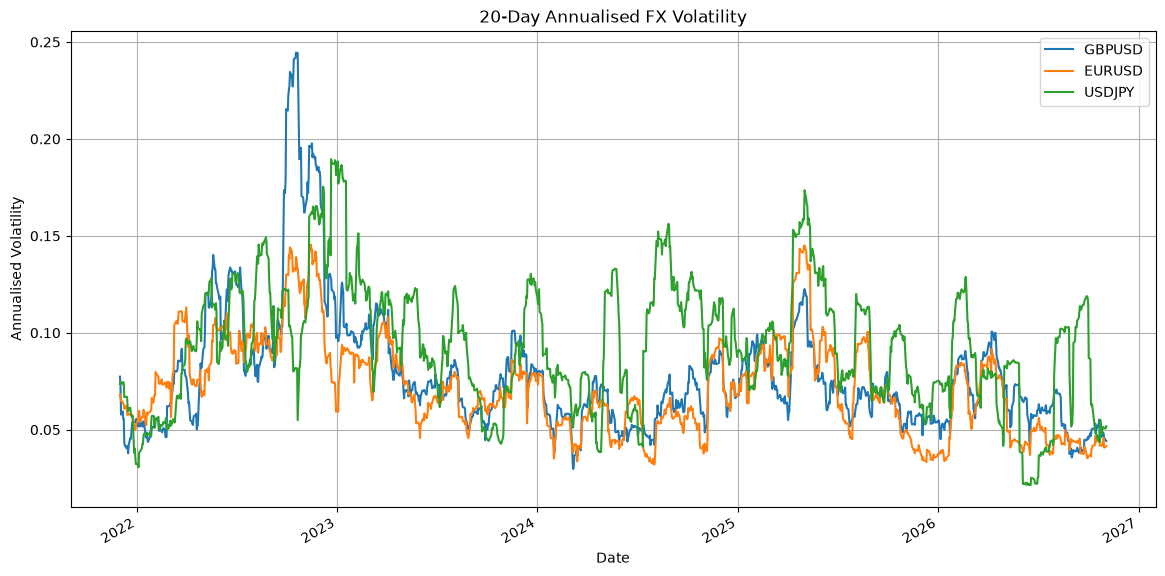

In [8]:
# Calculate 20-day rolling volatility
rolling_volatility = returns.rolling(window = 20).std()

# Annualise volatility
annualised_volatility = (rolling_volatility * np.sqrt(252))

# Plot annualised volatility 
annualised_volatility.plot(figsize = (14, 7), title = "20-Day Annualised FX Volatility")
plt.ylabel("Annualised Volatility")
plt.grid(True)
plt.show()

In [9]:
# Calculate squared daily returns
squared_returns = returns ** 2

# Display first observations
print(squared_returns.head())

                  GBPUSD        EURUSD        USDJPY
Date                                                
2021-11-04  3.219538e-05  9.805259e-06  8.972836e-07
2021-11-05  1.875601e-04  2.718043e-05  4.180837e-06
2021-11-08  1.648034e-06  1.363641e-06  1.014453e-05
2021-11-09  2.930852e-05  3.830409e-06  3.800435e-06
2021-11-10  1.103926e-07  1.209305e-07  9.146315e-06


<Figure size 1000x400 with 0 Axes>

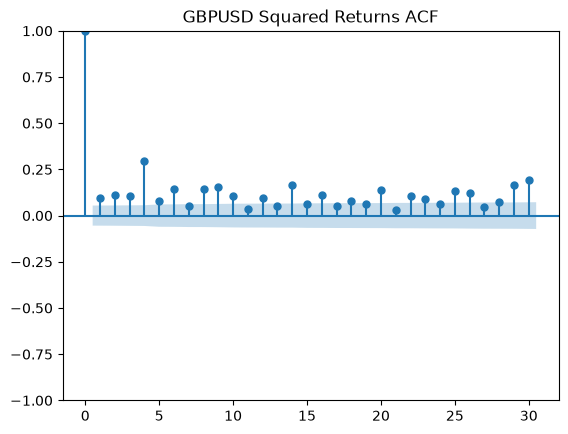

<Figure size 1000x400 with 0 Axes>

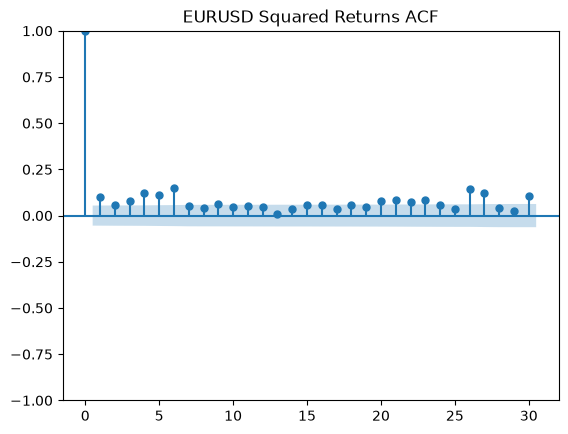

<Figure size 1000x400 with 0 Axes>

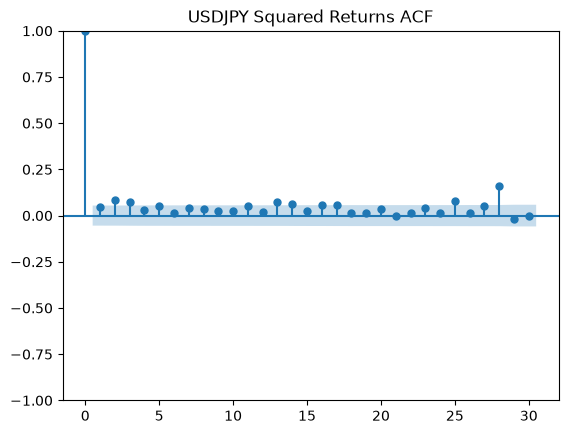

In [10]:
# Plot ACF for squared returns
for pair in squared_returns.columns:
    plt.figure(figsize = (10,4))
    plot_acf(squared_returns[pair], lags = 30, title = f"{pair} Squared Returns ACF")
    plt.tight_layout
    plt.show()

In [11]:
# Perform ARCM-LM tests
arch_results = {}
for pair in returns.columns:
    result = het_arch(returns[pair], nlags = 5)
    arch_results[pair] = {"LM Statistic": result[0], "P-Value": result[1], "F-Statistic": result[2], "F P-value": result[3]}

# Convert results into DataFrame
arch_df = pd.DataFrame(arch_results).T
print(arch_df) 

        LM Statistic       P-Value  F-Statistic     F P-value
GBPUSD    133.403697  4.508740e-27    29.609600  1.543727e-28
EURUSD     46.397796  7.536648e-09     9.580035  5.457829e-09
USDJPY     19.909801  1.299383e-03     4.025433  1.252573e-03


c:\Users\alexb\fx-risk-intelligence\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [17]:
# Compare ARCH effects across different lag lengths
for pair in returns.columns:

    print(f"\nResults for {pair}")
    for lag in [5, 10, 20]:
        result = het_arch(returns[pair],nlags = lag)

        print(
            f"Lags: {lag} | "
            f"LM Statistic: {result[0]:.4f} | "
            f"P-value: {result[1]:.6f}")


Results for GBPUSD
Lags: 5 | LM Statistic: 133.4037 | P-value: 0.000000
Lags: 10 | LM Statistic: 159.0380 | P-value: 0.000000
Lags: 20 | LM Statistic: 187.0762 | P-value: 0.000000

Results for EURUSD
Lags: 5 | LM Statistic: 46.3978 | P-value: 0.000000
Lags: 10 | LM Statistic: 65.1850 | P-value: 0.000000
Lags: 20 | LM Statistic: 73.9928 | P-value: 0.000000

Results for USDJPY
Lags: 5 | LM Statistic: 19.9098 | P-value: 0.001299
Lags: 10 | LM Statistic: 22.5754 | P-value: 0.012427
Lags: 20 | LM Statistic: 36.3754 | P-value: 0.013890
